In [1]:
import matplotlib.pyplot as plt
import sympy as sp
import numpy as np
from scipy.optimize import brentq
import pandas as pd

In [2]:
from values.constants import M_sun,c_val,G_val
from values.binary_data import name_binary,M_binary,M_err_binary,f_U_val_binary,f_U_err_binary,f_L_val_binary,f_L_err_binary
from values.metrics import metrics
from analysis.qpo_analysis import create_plot
from analysis.qpo_analysis import calc_freq
from analysis.qpo_analysis import stable_orbits_plot
from analysis.qpo_analysis import f_U_err_direct
from analysis.qpo_analysis import f_L_err_direct
from analysis.qpo_analysis import optimize_L
from analysis.qpo_analysis import optimized_dist
from analysis.qpo_analysis import global_dist
from analysis.qpo_analysis import max_L_horizon

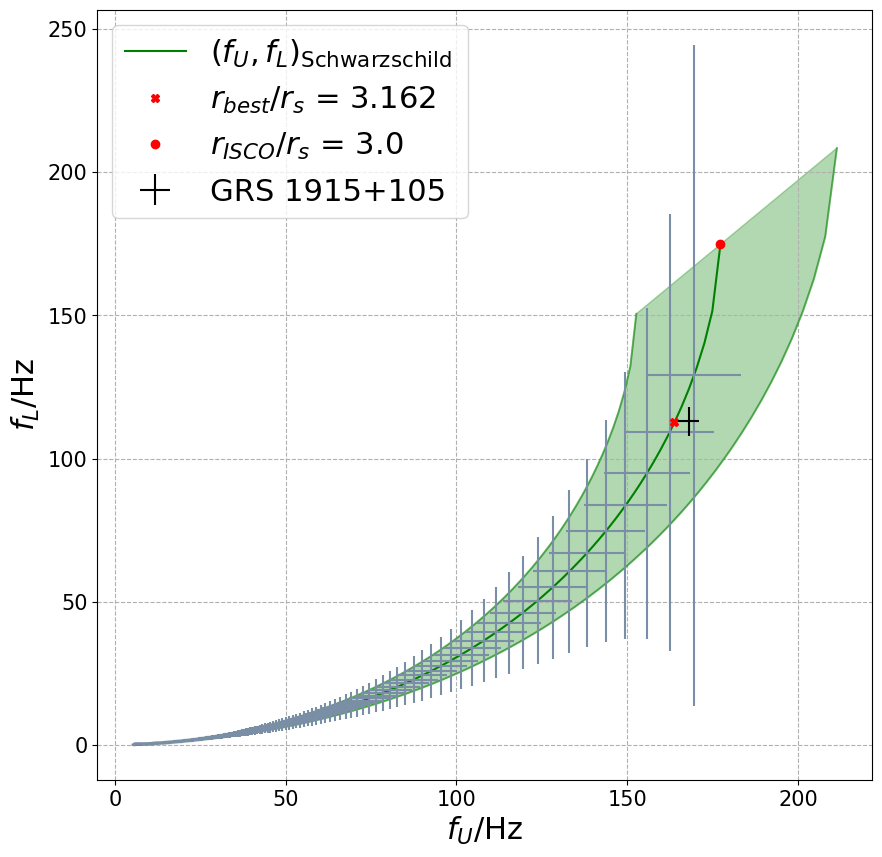

In [47]:
#------------------------
#choose metric
#------------------------
metric = metrics["s"]

#------------------------
#choose black hole
#------------------------
binary = 4

#------------------------
#choose L
#------------------------
L = G_val*M_binary[binary]*M_sun/c_val**2

create_plot(metric,binary,L,pltName="s_plot")

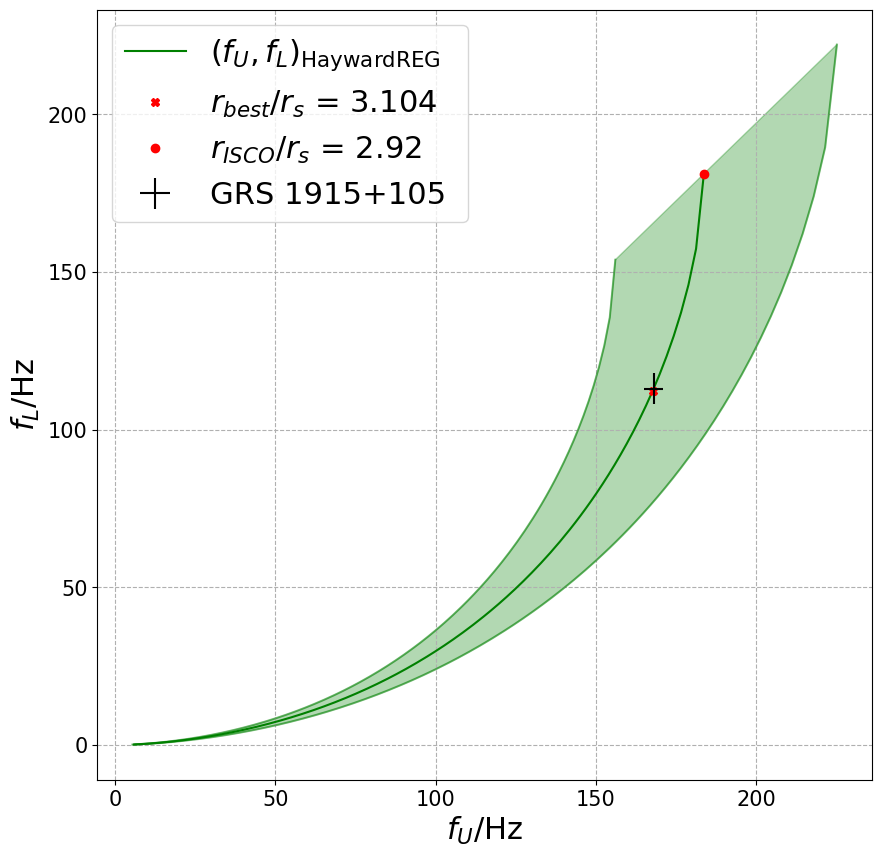

L in meters: 14515.769027401435


In [3]:
#------------------------
#choose metric
#------------------------
metric = metrics["h_REG"]

f_U_func,f_U_err_func,f_L_func,f_L_err_func,V_2diff,f,f_diff = calc_freq(metric)

#------------------------
#choose black hole
#------------------------
binary = 4

L = optimize_L(binary,f_U_func,f_U_err_direct,f_L_func,f_L_err_direct,V_2diff,f,f_diff)

create_plot(metric,binary,L,pltName="h_REG_fit")
print(f"L in meters: {L}")

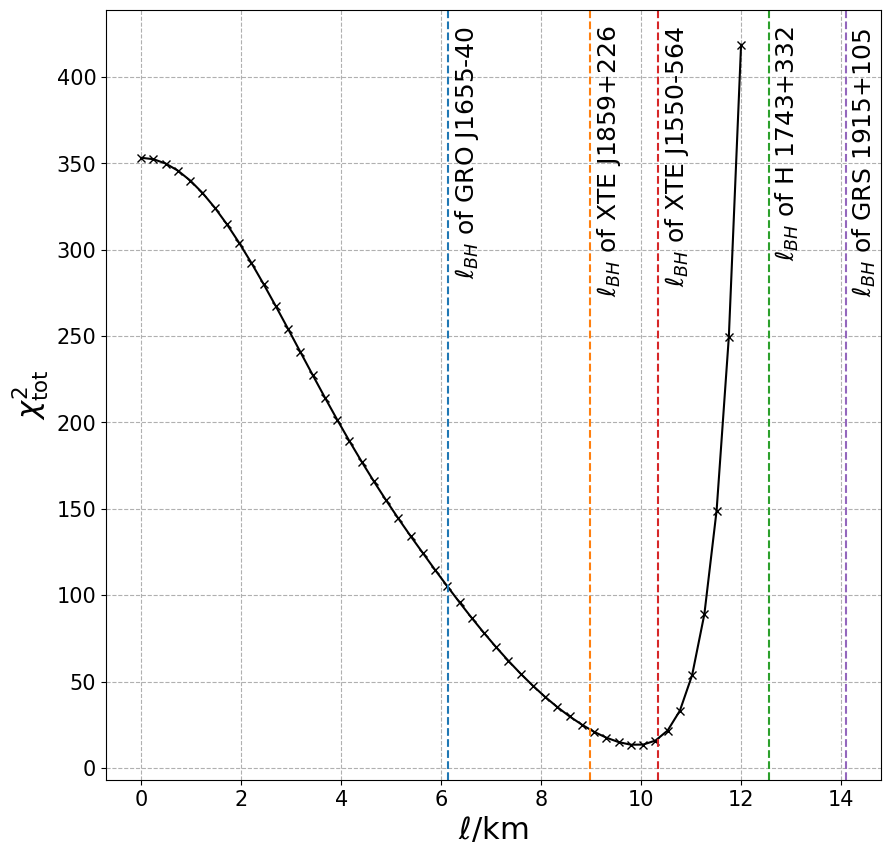

minimum of global $\chi^2$-fit: 13.416031031306366
minimum of global $\chi^2$-fit for all black holes: 104.53180893911092
minimum of individual $\chi^2$-fit: 5.108613390502566


In [49]:
plt.rcParams.update({'font.size': 22,'xtick.labelsize': 15,'ytick.labelsize': 15})
#------------------------
#choose metric
#------------------------
metric = metrics["h_LCC"]

f_U_func,f_U_err_func,f_L_func,f_L_err_func,V_2diff,f,f_diff = calc_freq(metric)

L = np.linspace(0,12000,50)
dist = global_dist(L,f_U_func,f_U_err_direct,f_L_func,f_L_err_direct,V_2diff,f,f_diff)

plt.plot(L/1000,dist,label=f"$\chi^2_{{\mathrm{{tot}}}}$",color="black")
plt.plot(L/1000,dist,"x",label=f"$\chi^2_{{\mathrm{{tot}}}}$",color="black")
L_max_array = []
for binary in range(len(M_binary)):
    L_max = max_L_horizon(M_binary[binary]*M_sun,f)
    L_max_array.append(L_max)
    plt.axvline(L_max/1000, linestyle='--',color=f"C{binary % 10}")
    plt.text(L_max/1000+0.1,0.98,rf"$\ell_{{BH}}$ of {name_binary[binary]}",fontsize=18,rotation=90,ha="left",va="top",transform=plt.gca().get_xaxis_transform())
plt.gcf().set_size_inches(10, 10)

plt.xlabel("$\ell$/km")
plt.ylabel("$\chi^2_{{\mathrm{{tot}}}}$")
plt.grid(linestyle="dashed")
plt.savefig("../results/h_LCC_chi_fit.png")
plt.show()

print(f"minimum of global $\chi^2$-fit: {min(dist)}")
L_BH = np.linspace(0,min(L_max_array),50)
print(f"minimum of global $\chi^2$-fit for all black holes: {min(global_dist(L_BH,f_U_func,f_U_err_direct,f_L_func,f_L_err_direct,V_2diff,f,f_diff))}")
print(f"minimum of individual $\chi^2$-fit: {optimized_dist(f_U_func,f_U_err_direct,f_L_func,f_L_err_direct,V_2diff,f,f_diff)}")

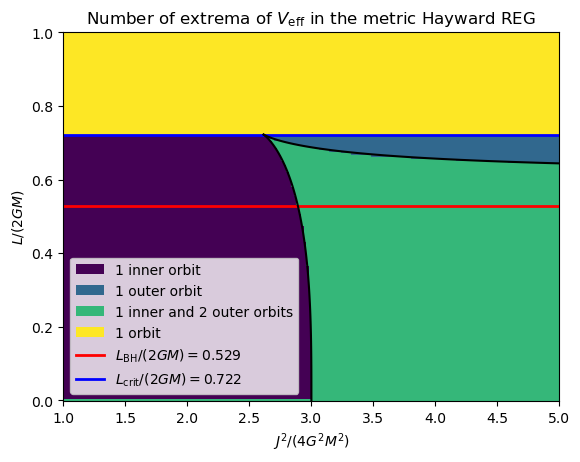

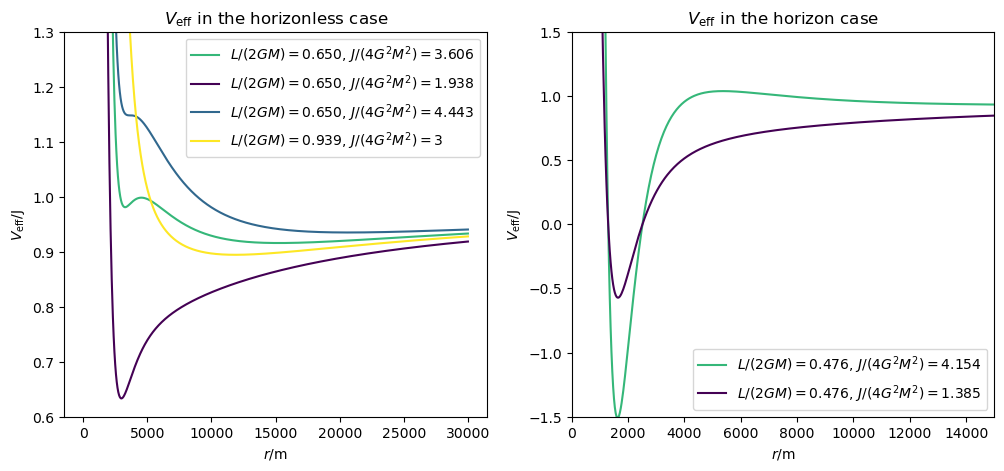

In [3]:
stable_orbits_plot(metrics["h_REG"],M_sun,max_L=1,example_functions=True, ISCO_line=True ,MSCO_line=True)